# AskPolicy: Fine-Tuning Mistral-7B-Instruct and Hybrid RAG Evaluation

**Pipeline overview**
1. Environment setup
2. Model loading and LoRA configuration
3. Dataset preparation
4. Fine-tuning (SFT) with evaluation metrics
5. Saving model artifacts
6. Reloading the fine-tuned model for inference
7. Hybrid retrieval (BM25 + FAISS + cross-encoder reranking)
8. Retrieval evaluation
9. End-to-end pipeline evaluation
10. Abstention evaluation (questions with no answer in the document)
11. Gradio demo interface

## 1. Environment Setup

In [1]:
!pip install -q langchain-community faiss-cpu sentence-transformers pypdf pdfplumber gradio trl rank_bm25 evaluate rouge_score

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.


In [2]:
%%capture
!pip install unsloth
!pip uninstall unsloth -y && pip install --upgrade --no-cache-dir --no-deps git+https://github.com/unslothai/unsloth.git

In [3]:
!pip install --upgrade --force-reinstall Pillow==11.3.0

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.6/6.6 MB 8.2 MB/s  0:00:00
  Attempting uninstall: Pillow
    Found existing installation: pillow 12.3.0
    Uninstalling pillow-12.3.0:
      Successfully uninstalled pillow-12.3.0
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
pdfplumber 0.11.10 requires Pillow>=12.2.0, but you have pillow 11.3.0 which is incompatible.


## 2. Model Loading and LoRA Configuration

In [ ]:
from unsloth import FastLanguageModel
import torch

max_seq_length = 2048
dtype = None
load_in_4bit = True

fourbit_models = [
    "unsloth/mistral-7b-bnb-4bit",
    "unsloth/mistral-7b-instruct-v0.2-bnb-4bit",
    "unsloth/llama-2-7b-bnb-4bit",
    "unsloth/llama-2-13b-bnb-4bit",
    "unsloth/codellama-34b-bnb-4bit",
    "unsloth/tinyllama-bnb-4bit",
    "unsloth/gemma-7b-bnb-4bit",
    "unsloth/gemma-2b-bnb-4bit",
]

model, tokenizer = FastLanguageModel.from_pretrained(
    model_name = "unsloth/mistral-7b-instruct-v0.2-bnb-4bit",
    max_seq_length = max_seq_length,
    dtype = dtype,
    load_in_4bit = load_in_4bit,
)

🦥 Unsloth: Will patch your computer to enable 2x faster free finetuning.


W1114 17:13:42.954000 818 torch/utils/_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
W1114 17:13:43.045000 818 torch/utils/_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


Unsloth: xformers is installed but cannot load with torch 2.14.1+cu130, so PyTorch attention is used instead.
To install a matching xformers, run `unsloth install-kernels xformers`, or `pip uninstall xformers` to hide this. UNSLOTH_ENABLE_LOGGING=1 shows the full error.
🦥 Unsloth Zoo will now patch everything to make training faster!
==((====))==  Unsloth 2026.11.4: Fast Mistral patching. Transformers: 5.17.0.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.14.1+cu130. CUDA: 7.5. CUDA Toolkit: 13.0. Triton: 3.8.0
\        /    Bfloat16 = FALSE. FA [Xformers = None. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


Loading weights:   0%|          | 0/291 [00:00<?, ?it/s]

In [ ]:
model = FastLanguageModel.get_peft_model(
    model,
    r = 16,
    target_modules = ["q_proj", "k_proj", "v_proj", "o_proj",
                      "gate_proj", "up_proj", "down_proj",],
    lora_alpha = 16,
    lora_dropout = 0,
    bias = "none",
    use_gradient_checkpointing = "unsloth",
    random_state = 3407,
    use_rslora = False,
    loftq_config = None,
)

Unsloth 2026.11.4 patched 32 layers with 32 QKV layers, 32 O layers and 32 MLP layers.


Unsloth: compiling each transformer block as one region (MistralDecoderLayer).


## 3. Dataset Preparation

In [ ]:
alpaca_prompt = """Below is an instruction that describes a task, paired with an input that provides further context. Write a response that appropriately completes the request.

### Instruction:
{}

### Input:
{}

### Response:
{}"""


EOS_TOKEN = tokenizer.eos_token
def formatting_prompts_func(examples):
    instructions = examples["instruction"]
    inputs       = examples["input"]
    outputs      = examples["output"]
    texts = []
    for instruction, input, output in zip(instructions, inputs, outputs):
        text = alpaca_prompt.format(instruction, input, output) + EOS_TOKEN
        texts.append(text)
    return { "text" : texts, }
pass

In [ ]:
import os
if os.path.exists("/content/train_data.json"):
    print("File found!")
else:
    print("File not found. Please check the path and ensure the file is uploaded or correctly placed.")

from datasets import load_dataset
dataset = load_dataset("json", data_files="/content/train_data.json", split="train")
dataset = dataset.map(formatting_prompts_func, batched = True,)
dataset = dataset.train_test_split(test_size=0.2)


train_dataset = dataset["train"]
test_dataset = dataset["test"]

File found!


## 4. Fine-Tuning

### 4.1 Evaluation Metrics

In [ ]:
from sentence_transformers import SentenceTransformer, util
import evaluate

sbert_model = SentenceTransformer("mixedbread-ai/mxbai-embed-large-v1")
bleu_metric = evaluate.load("bleu")

def compute_metrics(eval_preds):
    predictions, labels = eval_preds

    if isinstance(predictions, tuple):
        predictions = predictions[0]

    predictions = predictions.tolist()
    labels = labels.tolist()

    decoded_preds = []
    decoded_labels = []

    for i in range(len(predictions)):
        label_row = labels[i]
        pred_row = predictions[i]

        # Logits at position t-1 predict the token at position t
        resp_label_ids = []
        resp_pred_ids = []
        for t, lab in enumerate(label_row):
            if lab != -100:
                resp_label_ids.append(lab)
                pred_pos = t - 1 if t - 1 >= 0 else t
                resp_pred_ids.append(pred_row[pred_pos])

        decoded_preds.append(tokenizer.decode(resp_pred_ids, skip_special_tokens=True).strip())
        decoded_labels.append(tokenizer.decode(resp_label_ids, skip_special_tokens=True).strip())

    # BLEU-4 (default max_order=4)
    bleu_4 = bleu_metric.compute(
        predictions=decoded_preds,
        references=[[label] for label in decoded_labels]
    )

    # BLEU-2
    bleu_2 = bleu_metric.compute(
        predictions=decoded_preds,
        references=[[label] for label in decoded_labels],
        max_order=2
    )

    # Semantic similarity (SBERT)
    embeddings_preds = sbert_model.encode(decoded_preds, convert_to_tensor=True)
    embeddings_labels = sbert_model.encode(decoded_labels, convert_to_tensor=True)
    cosine_scores = util.cos_sim(embeddings_preds, embeddings_labels).diagonal()
    avg_semantic_similarity = cosine_scores.mean().item()

    return {
        "bleu_4": bleu_4["bleu"],
        "bleu_2": bleu_2["bleu"],
        "semantic_similarity": avg_semantic_similarity
    }


# Reduces logits to token ids before accumulation to avoid GPU OOM during evaluation
def preprocess_logits_for_metrics(logits, labels):
    if isinstance(logits, tuple):
        logits = logits[0]
    return logits.argmax(dim=-1)

Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

### 4.2 Periodic Evaluation Callback

In [ ]:
from collections import defaultdict
from transformers import TrainerCallback

eval_results = defaultdict(list)
eval_steps = 5

class CustomEvalCallback(TrainerCallback):
    def __init__(self, trainer, eval_steps):
        self.trainer = trainer
        self.eval_steps = eval_steps

    def on_train_begin(self, args, state, control, **kwargs):
        pass

    def on_step_end(self, args, state, control, **kwargs):
        if state.global_step % self.eval_steps == 0:
            eval_metrics = self.trainer.evaluate()
            eval_results["step"].append(state.global_step)
            eval_results["eval_loss"].append(eval_metrics.get("eval_loss"))
            eval_results["bleu_4"].append(eval_metrics.get("eval_bleu_4"))
            eval_results["bleu_2"].append(eval_metrics.get("eval_bleu_2"))
            eval_results["semantic_similarity"].append(eval_metrics.get("eval_semantic_similarity"))
            print(f"\nEvaluation at step {state.global_step}:")
            print(f"  Eval Loss: {eval_metrics.get('eval_loss')}")
            print(f"  BLEU-4: {eval_metrics.get('eval_bleu_4')}")
            print(f"  BLEU-2: {eval_metrics.get('eval_bleu_2')}")
            print(f"  Semantic Similarity: {eval_metrics.get('eval_semantic_similarity')}")
        return control

### 4.3 Trainer Configuration

In [ ]:
from trl import SFTTrainer
from transformers import TrainingArguments
from transformers.utils.notebook import NotebookProgressCallback
from unsloth import is_bfloat16_supported


training_args = TrainingArguments(
    per_device_train_batch_size = 2,
    per_device_eval_batch_size = 2,
    gradient_accumulation_steps = 4,
    warmup_steps = 5,
    max_steps = 250,
    learning_rate = 2e-5,
    fp16 = False,
    logging_steps = 1,
    optim = "adamw_8bit",
    weight_decay = 0.1,
    lr_scheduler_type = "linear",
    seed = 3407,
    output_dir = "outputs",
    report_to = "none",
    save_strategy = "steps",
    save_steps = 20,
)


trainer = SFTTrainer(
    model = model,
    tokenizer = tokenizer,
    train_dataset = train_dataset,
    eval_dataset = test_dataset,
    dataset_text_field = "text",
    max_seq_length = max_seq_length,
    dataset_num_proc = 2,
    packing = True,
    args = training_args,
    compute_metrics = compute_metrics,
    preprocess_logits_for_metrics = preprocess_logits_for_metrics,
)

trainer.remove_callback(NotebookProgressCallback)
trainer.add_callback(CustomEvalCallback(trainer, eval_steps))

Unsloth: Tokenizing ["text"] (num_proc=2):   0%|          | 0/240 [00:00<?, ? examples/s]

Unsloth: Tokenizing ["text"] (num_proc=2):   0%|          | 0/60 [00:00<?, ? examples/s]

### 4.4 Training and Final Evaluation

In [ ]:
import os
os.environ["UNSLOTH_RETURN_LOGITS"] = "1"

trainer_stats = trainer.train()

try:
    eval_metrics = trainer.evaluate()
except RuntimeError as e:
    print(f"Standalone evaluate() failed ({e}), reusing last evaluation from training.")
    eval_metrics = {
        "eval_loss": eval_results["eval_loss"][-1] if eval_results["eval_loss"] else None,
        "eval_bleu_4": None,
        "eval_bleu_2": None,
        "eval_semantic_similarity": None,
    }

==((====))==  Unsloth - 2x faster free finetuning | Num GPUs used = 1
   \\   /|    Num examples = 240 | Num Epochs = 9 | Total steps = 250
O^O/ \_/ \    Batch size per device = 2 | Gradient accumulation steps = 4
\        /    Data Parallel GPUs = 1 | Total batch size (2 x 4 x 1) = 8
 "-____-"     Trainable parameters = 41,943,040 of 7,283,675,136 (0.58% trained)


Unsloth: Will smartly offload gradients to save VRAM!
Unsloth: Double buffering enabled (parallel H2D + compute) for backward pass.


Unsloth: Not an error, but `num_items_in_batch` could not be counted for MistralForCausalLM's labels, so each micro-batch loss is a mean.
Using gradient accumulation will be very slightly less accurate.
Read more on gradient accumulation issues here: https://unsloth.ai/blog/gradient



Evaluation at step 5:
  Eval Loss: 2.3378570079803467
  BLEU-4: 0.3022841293589236
  BLEU-2: 0.4671490253058133
  Semantic Similarity: 0.8808493614196777

Evaluation at step 10:
  Eval Loss: 1.8075846433639526
  BLEU-4: 0.4009217863255167
  BLEU-2: 0.5347444290572332
  Semantic Similarity: 0.9028776288032532

Evaluation at step 15:
  Eval Loss: 1.5416148900985718
  BLEU-4: 0.4203404928564039
  BLEU-2: 0.5520081966073733
  Semantic Similarity: 0.9036247730255127

Evaluation at step 20:
  Eval Loss: 1.3451812267303467
  BLEU-4: 0.5079447995733897
  BLEU-2: 0.6297832969866394
  Semantic Similarity: 0.9021787047386169


Unsloth: Restored added_tokens_decoder metadata in outputs/checkpoint-20/tokenizer_config.json.
Unsloth: Preserved sentencepiece asset `tokenizer.model` in outputs/checkpoint-20.



Evaluation at step 25:
  Eval Loss: 1.2075040340423584
  BLEU-4: 0.5253936484766834
  BLEU-2: 0.6459479569807031
  Semantic Similarity: 0.9023038148880005

Evaluation at step 30:
  Eval Loss: 1.114827036857605
  BLEU-4: 0.563014392074291
  BLEU-2: 0.6738953203068664
  Semantic Similarity: 0.8853359818458557

Evaluation at step 35:
  Eval Loss: 1.0737297534942627
  BLEU-4: 0.5788371516702977
  BLEU-2: 0.6868793707106482
  Semantic Similarity: 0.8870299458503723

Evaluation at step 40:
  Eval Loss: 1.0467560291290283
  BLEU-4: 0.5833706057391241
  BLEU-2: 0.6899795395982347
  Semantic Similarity: 0.8890775442123413


... (19 outputs left out)


Evaluation at step 225:
  Eval Loss: 0.9015219807624817
  BLEU-4: 0.6124063160557873
  BLEU-2: 0.7156817394856368
  Semantic Similarity: 0.8968067765235901

Evaluation at step 230:
  Eval Loss: 0.9023973941802979
  BLEU-4: 0.612709203210262
  BLEU-2: 0.7157026947583124
  Semantic Similarity: 0.8966440558433533

Evaluation at step 235:
  Eval Loss: 0.9020348787307739
  BLEU-4: 0.611971463957641
  BLEU-2: 0.7151892311139821
  Semantic Similarity: 0.8967300653457642

Evaluation at step 240:
  Eval Loss: 0.9011029005050659
  BLEU-4: 0.612692601681963
  BLEU-2: 0.7160460137023743
  Semantic Similarity: 0.8970549702644348


Unsloth: Restored added_tokens_decoder metadata in outputs/checkpoint-240/tokenizer_config.json.
Unsloth: Preserved sentencepiece asset `tokenizer.model` in outputs/checkpoint-240.



Evaluation at step 245:
  Eval Loss: 0.9007852673530579
  BLEU-4: 0.6128615775115104
  BLEU-2: 0.7159714061466935
  Semantic Similarity: 0.8969655632972717

Evaluation at step 250:
  Eval Loss: 0.900734543800354
  BLEU-4: 0.612469877272182
  BLEU-2: 0.7158967908157478
  Semantic Similarity: 0.8970022797584534


Unsloth: Restored added_tokens_decoder metadata in outputs/checkpoint-250/tokenizer_config.json.
Unsloth: Preserved sentencepiece asset `tokenizer.model` in outputs/checkpoint-250.


In [ ]:
train_loss = trainer_stats.training_loss if hasattr(trainer_stats, 'training_loss') else None
eval_loss = eval_metrics.get("eval_loss", None)
bleu_4 = eval_metrics.get("eval_bleu_4", None)
bleu_2 = eval_metrics.get("eval_bleu_2", None)
semantic_score = eval_metrics.get("eval_semantic_similarity", None)
perplexity = torch.exp(torch.tensor(eval_loss)) if eval_loss is not None else None

print(f"\nTrain Loss: {train_loss}")
print(f"Eval Loss: {eval_loss}")
print(f"BLEU-4 Score: {bleu_4}")
print(f"BLEU-2 Score: {bleu_2}")
print(f"Semantic Similarity: {semantic_score}")
print(f"Perplexity: {perplexity}")

print("\n=== Evaluation Metrics ===")
print(eval_metrics)


Train Loss: 0.8722331013679504
Eval Loss: 0.9007337093353271
BLEU-4 Score: 0.612469877272182
BLEU-2 Score: 0.7158967908157478
Semantic Similarity: 0.8970022797584534
Perplexity: 2.4614083766937256

=== Evaluation Metrics ===
{'eval_loss': 0.9007337093353271, 'eval_bleu_4': 0.612469877272182, 'eval_bleu_2': 0.7158967908157478, 'eval_semantic_similarity': 0.8970022797584534, 'eval_runtime': 14.1991, 'eval_samples_per_second': 4.226, 'eval_steps_per_second': 2.113, 'epoch': 8.333333333333334}


### 4.5 Loss Curves

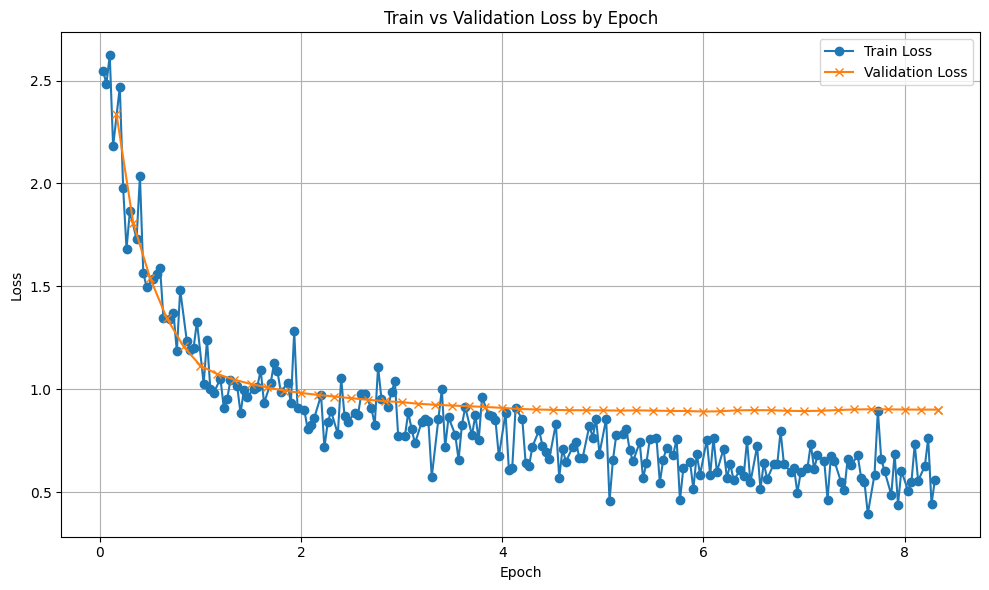

In [ ]:
import matplotlib.pyplot as plt

train_epochs = []
train_losses = []
eval_epochs = []
eval_losses = []

for log in trainer.state.log_history:
    if 'loss' in log and 'epoch' in log:
        train_epochs.append(log['epoch'])
        train_losses.append(log['loss'])
    elif 'eval_loss' in log and 'epoch' in log:
        eval_epochs.append(log['epoch'])
        eval_losses.append(log['eval_loss'])

plt.figure(figsize=(10, 6))
plt.plot(train_epochs, train_losses, label="Train Loss", marker='o')
plt.plot(eval_epochs, eval_losses, label="Validation Loss", marker='x')

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Train vs Validation Loss by Epoch")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

## 5. Saving Model Artifacts

In [ ]:
pip freeze > mistral-requirements.txt

In [ ]:
model.save_pretrained("my_lora_adapter")
tokenizer.save_pretrained("my_tokenizer")

Unsloth: Restored added_tokens_decoder metadata in my_tokenizer/tokenizer_config.json.
Unsloth: Preserved sentencepiece asset `tokenizer.model` in my_tokenizer.


('my_tokenizer/tokenizer_config.json',
 'my_tokenizer/chat_template.jinja',
 'my_tokenizer/tokenizer.json')

In [ ]:
from huggingface_hub import snapshot_download

snapshot_download(
    repo_id="unsloth/mistral-7b-instruct-v0.2-bnb-4bit",
    local_dir="mistral_7b_v02_frozen",
    local_dir_use_symlinks=False
)

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 10 files:   0%|          | 0/10 [00:00<?, ?it/s]

'/content/mistral_7b_v02_frozen'

In [ ]:
import shutil

shutil.make_archive("my_lora_adapter", 'zip', "my_lora_adapter")
shutil.make_archive("my_tokenizer", 'zip', "my_tokenizer")
shutil.make_archive("mistral_7b_v02_frozen", 'zip', "mistral_7b_v02_frozen")

'/content/mistral_7b_v02_frozen.zip'

In [ ]:
from google.colab import files

files.download("my_lora_adapter.zip")
files.download("my_tokenizer.zip")
files.download("mistral_7b_v02_frozen.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 6. Reloading the Fine-Tuned Model for Inference

### 6.1 Environment Setup

In [8]:
!pip install -q langchain-community faiss-cpu sentence-transformers pypdf pdfplumber gradio trl rank_bm25 evaluate rouge_score

In [ ]:
!pip install transformers accelerate peft bitsandbytes

In [10]:
%%capture
!pip install unsloth
!pip uninstall unsloth -y && pip install --upgrade --no-cache-dir --no-deps git+https://github.com/unslothai/unsloth.git

In [ ]:
!pip install --upgrade --force-reinstall Pillow==11.3.0

In [12]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


### 6.2 Extracting Artifacts

In [ ]:
from google.colab import drive
import os
import shutil
from transformers import AutoTokenizer, AutoModelForCausalLM
from peft import PeftModel
import torch

# "models-askpolicy" The drive folder containing the saved models. Change if needed.
base_zip = "/content/drive/MyDrive/models-askpolicy/mistral_7b_v02_frozen.zip"
adapter_zip = "/content/drive/MyDrive/models-askpolicy/my_lora_adapter.zip"
tokenizer_zip = "/content/drive/MyDrive/models-askpolicy/my_tokenizer.zip"

base_dir = "/content/mistral_7b_v02_frozen"
adapter_dir = "/content/my_lora_adapter"
tokenizer_dir = "/content/my_tokenizer"

def safe_unzip(zip_path, extract_to):
    if not os.path.exists(extract_to):
        os.makedirs(extract_to, exist_ok=True)
        shutil.unpack_archive(zip_path, extract_to)
        print(f"[+] Extracted to {extract_to}")
    else:
        print(f"[!] Folder already exists: {extract_to}")

safe_unzip(base_zip, base_dir)
safe_unzip(adapter_zip, adapter_dir)
safe_unzip(tokenizer_zip, tokenizer_dir)

W1115 08:19:52.079000 1366 torch/utils/_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
W1115 08:19:52.169000 1366 torch/utils/_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


[+] Extracted to /content/mistral_7b_v02_frozen
[+] Extracted to /content/my_lora_adapter
[+] Extracted to /content/my_tokenizer


### 6.3 Loading Model and Tokenizer

In [ ]:
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig
from peft import PeftModel
import torch

print("[+] Loading tokenizer...")
tokenizer = AutoTokenizer.from_pretrained(tokenizer_dir)

print("[+] Configuring 4-bit quantization...")
bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.float16,
    bnb_4bit_use_double_quant=True,
)

print("[+] Loading base model (4-bit)...")
model = AutoModelForCausalLM.from_pretrained(
    base_dir,
    quantization_config=bnb_config,
    device_map="auto",
    trust_remote_code=True,
)

print("[+] Attaching LoRA adapter...")
model = PeftModel.from_pretrained(model, adapter_dir)

model.eval()

print("[✅] Model and tokenizer are ready.")


[+] Loading tokenizer...
[+] Configuring 4-bit quantization...
[+] Loading base model (4-bit)...


/usr/local/lib/python3.13/dist-packages/transformers/quantizers/auto.py:279: UserWarning: You passed `quantization_config` or equivalent parameters to `from_pretrained` but the model you're loading already has a `quantization_config` attribute. The `quantization_config` from the model will be used.
  warnings.warn(warning_msg)


Loading weights:   0%|          | 0/291 [00:00<?, ?it/s]

[+] Attaching LoRA adapter...
[✅] Model and tokenizer are ready.


### 6.4 Sanity Checks

In [15]:
print("[Base model info]")
print("Model type:", model.base_model.model.__class__.__name__)
print("Hidden size:", model.config.hidden_size)
print("Model name:", model.config._name_or_path)

[Base model info]
Model type: MistralForCausalLM
Hidden size: 4096
Model name: /content/mistral_7b_v02_frozen


In [16]:
from peft import get_peft_model_state_dict

lora_keys = list(get_peft_model_state_dict(model).keys())
print(f"[LoRA] Loaded {len(lora_keys)} LoRA adapter weights.")
print("Example keys:", lora_keys[:5])

config.json:   0%|          | 0.00/1.20k [00:00<?, ?B/s]

[LoRA] Loaded 448 LoRA adapter weights.
Example keys: ['base_model.model.model.layers.0.self_attn.q_proj.lora_A.weight', 'base_model.model.model.layers.0.self_attn.q_proj.lora_B.weight', 'base_model.model.model.layers.0.self_attn.k_proj.lora_A.weight', 'base_model.model.model.layers.0.self_attn.k_proj.lora_B.weight', 'base_model.model.model.layers.0.self_attn.v_proj.lora_A.weight']


In [17]:
print("[Tokenizer info]")
print("Vocab size:", len(tokenizer))
print("Tokenizer class:", tokenizer.__class__.__name__)
print("Pad token:", tokenizer.pad_token)
print("EOS token:", tokenizer.eos_token)

[Tokenizer info]
Vocab size: 32000
Tokenizer class: LlamaTokenizer
Pad token: <unk>
EOS token: </s>


### 6.5 Prompt Template

In [18]:
alpaca_prompt = """Below is an instruction that describes a task, paired with an input that provides further context. Write a response that appropriately completes the request.

### Instruction:
{}

### Input:
{}

### Response:
{}"""


EOS_TOKEN = tokenizer.eos_token
def formatting_prompts_func(examples):
    instructions = examples["instruction"]
    inputs       = examples["input"]
    outputs      = examples["output"]
    texts = []
    for instruction, input, output in zip(instructions, inputs, outputs):
        text = alpaca_prompt.format(instruction, input, output) + EOS_TOKEN
        texts.append(text)
    return { "text" : texts, }
pass

## 7. Hybrid Retrieval-Augmented Generation (BM25 + FAISS)

### 7.1 Models and Text Preprocessing

In [19]:
from unsloth import FastLanguageModel
import torch
from sentence_transformers import SentenceTransformer, CrossEncoder, util
from langchain_community.vectorstores import FAISS
from langchain_community.embeddings import HuggingFaceEmbeddings
from langchain_text_splitters import RecursiveCharacterTextSplitter
from rank_bm25 import BM25Okapi
import pdfplumber
import numpy as np
import logging
import re
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import PorterStemmer
from langchain_community.vectorstores.utils import DistanceStrategy


nltk.download("punkt")
nltk.download("stopwords")
nltk.download('punkt_tab')


stop_words = set(stopwords.words("english"))
stemmer = PorterStemmer()

sbert_model = SentenceTransformer("mixedbread-ai/mxbai-embed-large-v1")
cross_encoder = CrossEncoder("BAAI/bge-reranker-large")

🦥 Unsloth: Will patch your computer to enable 2x faster free finetuning.


/usr/local/lib/python3.13/dist-packages/unsloth/__init__.py:2170: UserWarning: WARNING: Unsloth should be imported before [transformers, peft] to ensure all optimizations are applied. Your code may run slower or encounter memory issues without these optimizations.

Please restructure your imports with 'import unsloth' at the top of your file.
  from ._gpu_init import *


Unsloth: xformers is installed but cannot load with torch 2.14.1+cu130, so PyTorch attention is used instead.
To install a matching xformers, run `unsloth install-kernels xformers`, or `pip uninstall xformers` to hide this. UNSLOTH_ENABLE_LOGGING=1 shows the full error.
🦥 Unsloth Zoo will now patch everything to make training faster!


/tmp/ipykernel_1366/3130178270.py:4: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.vectorstores import FAISS
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


modules.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/266 [00:00<?, ?B/s]

... (17 outputs left out)

sentencepiece.bpe.model: downloading bytes:           |  0.00B            

tokenizer.json: reconstructing file:   0%|          |  0.00B / 17.1MB            

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/279 [00:00<?, ?B/s]

### 7.2 Document Indexing

In [ ]:
text_splitter = RecursiveCharacterTextSplitter(
    chunk_size=400,
    chunk_overlap=150,
    separators=["\n\n", "\n", ". "]
)

embeddings = HuggingFaceEmbeddings(
    model_name="mixedbread-ai/mxbai-embed-large-v1",
    model_kwargs={"device": "cpu"},
    encode_kwargs={"normalize_embeddings": True}
)

def tokenize(text):
    return [
        stemmer.stem(w)
        for w in word_tokenize(text.lower())
        if w.isalnum() and w.lower() not in stop_words
    ]

def load_document(file_path):
    if file_path.endswith(".pdf"):
        with pdfplumber.open(file_path) as pdf:
            text = "\n".join([page.extract_text() or '' for page in pdf.pages])
    else:
        with open(file_path, "r", encoding="utf-8") as file:
            text = file.read()
    if not text.strip():
        raise ValueError("Document is empty or could not be parsed.")
    return text

def normalize_output(text):
    text = re.sub(r'\s+', ' ', text)
    text = re.sub(r'[\•\-\–\*]\s+', '', text)
    text = re.sub(r'\b\d+\.\s+', '', text)
    text = re.sub(r'\.(\S)', r'. \1', text)
    return text.strip()


def create_hybrid_db(file_path):
    try:
        text = load_document(file_path)
        chunks = text_splitter.split_text(text)
        chunks = [c for c in chunks if len(c.split()) > 10 and len(c.strip()) > 30]
        tokenized_chunks = [tokenize(chunk) for chunk in chunks]
        bm25 = BM25Okapi(tokenized_chunks)
        faiss = FAISS.from_texts(chunks, embeddings, distance_strategy=DistanceStrategy.MAX_INNER_PRODUCT)
        return {
            "chunks": chunks,
            "tokenized": tokenized_chunks,
            "bm25": bm25,
            "faiss": faiss
        }
    except Exception as e:
        print(f"[ERROR] Failed to load document: {e}")
        return None

/tmp/ipykernel_1366/2745108768.py:7: LangChainDeprecationWarning: The class `HuggingFaceEmbeddings` was deprecated in LangChain 0.2.2 and will be removed in 1.0. An updated version of the class exists in the `langchain-huggingface package and should be used instead. To use it run `pip install -U `langchain-huggingface` and import as `from `langchain_huggingface import HuggingFaceEmbeddings``.
  embeddings = HuggingFaceEmbeddings(


Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

### 7.3 Context Retrieval

In [21]:
def retrieve_context(question, db, k=5, top_k=1, alpha=0.5):
    threshold = 40.0
    sbert_threshold = 0.60
    if db is None:
        return "No context found.", 0.0

    bm25_chunks = db["chunks"]
    bm25 = db["bm25"]
    faiss = db["faiss"]

    # BM25 candidates
    bm25_scores_raw = bm25.get_scores(tokenize(question))
    top_bm25 = sorted(zip(bm25_chunks, bm25_scores_raw), key=lambda x: x[1], reverse=True)[:k]

    # FAISS candidates
    faiss_results = faiss.similarity_search_with_score(question, k=k)
    top_faiss = [(doc.page_content, score) for doc, score in faiss_results]

    # Merge candidates (deduplicated by normalized text)
    combined_chunks_dict = {}
    for chunk, score in top_bm25 + top_faiss:
        norm_chunk = normalize_output(chunk)
        if norm_chunk not in combined_chunks_dict:
            combined_chunks_dict[norm_chunk] = {
                "original": chunk,
                "bm25_score": 0.0,
                "faiss_score": 0.0
            }

    bm25_scores_map = {normalize_output(c): s for c, s in top_bm25}
    for norm_chunk in combined_chunks_dict:
        if norm_chunk in bm25_scores_map:
            combined_chunks_dict[norm_chunk]["bm25_score"] = bm25_scores_map[norm_chunk]

    faiss_scores_map = {normalize_output(c): s for c, s in top_faiss}
    for norm_chunk in combined_chunks_dict:
        if norm_chunk in faiss_scores_map:
            combined_chunks_dict[norm_chunk]["faiss_score"] = faiss_scores_map[norm_chunk]

    # Min-max normalization of each score type
    bm25_vals = [v["bm25_score"] for v in combined_chunks_dict.values()]
    faiss_vals = [v["faiss_score"] for v in combined_chunks_dict.values()]

    def normalize_scores(scores):
        min_s = min(scores)
        max_s = max(scores)
        if max_s - min_s == 0:
            return [0.0 for _ in scores]
        return [(s - min_s) / (max_s - min_s) for s in scores]

    bm25_norm = normalize_scores(bm25_vals)
    faiss_norm = normalize_scores(faiss_vals)

    # Weighted score fusion
    for i, norm_chunk in enumerate(combined_chunks_dict):
        combined_chunks_dict[norm_chunk]["combined_score"] = (
            alpha * faiss_norm[i] + (1 - alpha) * bm25_norm[i]
        )

    sorted_candidates = sorted(
        combined_chunks_dict.values(),
        key=lambda x: x["combined_score"],
        reverse=True
    )

    candidates_for_rerank = [c["original"] for c in sorted_candidates[:k]]

    # Cross-encoder reranking
    pairs = [(question, chunk) for chunk in candidates_for_rerank]
    rerank_scores = cross_encoder.predict(pairs, batch_size=8, activation_fct=torch.nn.Identity())
    reranked = sorted(zip(candidates_for_rerank, rerank_scores), key=lambda x: x[1], reverse=True)

    top_chunks = [chunk for chunk, _ in reranked[:top_k]]
    avg_score = np.mean([score for _, score in reranked[:top_k]])
    confidence = 1 / (1 + np.exp(-avg_score)) * 100

    sbert_sim = util.cos_sim(
        sbert_model.encode(question, convert_to_tensor=True),
        sbert_model.encode(" ".join(top_chunks), convert_to_tensor=True)
    ).item()

    print(f"[INFO] Cross-encoder confidence: {confidence:.2f}%, SBERT similarity: {sbert_sim:.2f}")

    if confidence < threshold or sbert_sim < sbert_threshold:
        return "No relevant clause was found.", confidence

    return f"[Document Clause]: {normalize_output(top_chunks[0])}", confidence

### 7.4 Answer Generation

In [22]:
def answer_with_rag(question, db, gold_chunk=None):
    context, score = retrieve_context(question, db, alpha=0.5)
    print("=== RETRIEVED CONTEXT ===")
    print(context)
    print(f"\nSimilarity Score: {score:.2f}%\n")

    if gold_chunk:
        sbert_sim = util.cos_sim(
            sbert_model.encode(context, convert_to_tensor=True),
            sbert_model.encode(gold_chunk, convert_to_tensor=True)
        ).item() * 100
        print(f"SBERT Similarity (retrieved vs gold): {sbert_sim:.2f}%")

    prompt = alpaca_prompt.format(question, context, "")
    inputs = tokenizer([prompt], return_tensors="pt").to("cuda")

    outputs = model.generate(**inputs, max_new_tokens=256)
    answer = tokenizer.decode(outputs[0], skip_special_tokens=True)
    answer = answer.split("### Response:")[-1].strip()

    print("=== MODEL ANSWER ===")
    print(answer)
    return answer

## 8. Retrieval Evaluation

### 8.1 Evaluation Helpers

In [23]:
import os
import json
import math
import numpy as np
from glob import glob
from tqdm import tqdm
from sklearn.feature_extraction.text import TfidfVectorizer
from sentence_transformers import SentenceTransformer, CrossEncoder, util

sbert = sbert_model
cross = cross_encoder

def contains_answer_semantically(gold_answer, docs, threshold=0.75):
    gold_emb = sbert.encode(gold_answer, convert_to_tensor=True)
    doc_embs = sbert.encode(docs, convert_to_tensor=True)
    sims = util.cos_sim(gold_emb, doc_embs)[0]
    return any(sim.item() > threshold for sim in sims)

def compute_ndcg(relevance, k):
    dcg = 0.0
    for i in range(min(k, len(relevance))):
        if relevance[i]:
            dcg += 1 / math.log2(i + 2)

    ideal_relevance = sorted(relevance, reverse=True)
    idcg = 0.0
    for i in range(min(k, len(ideal_relevance))):
        if ideal_relevance[i]:
            idcg += 1 / math.log2(i + 2)

    return dcg / idcg if idcg > 0 else 0.0

In [24]:
import os
import json
import math
import numpy as np
from glob import glob
from tqdm import tqdm
from sklearn.feature_extraction.text import TfidfVectorizer
from sentence_transformers import SentenceTransformer, CrossEncoder, util

sbert = sbert_model
cross = cross_encoder

def contains_answer_semantically(gold_answer, docs, threshold=0.75):
    gold_emb = sbert.encode(gold_answer, convert_to_tensor=True)
    doc_embs = sbert.encode(docs, convert_to_tensor=True)
    sims = util.cos_sim(gold_emb, doc_embs)[0]
    return any(sim.item() > threshold for sim in sims)

def compute_ndcg(relevance, k):
    dcg = 0.0
    for i in range(min(k, len(relevance))):
        if relevance[i]:
            dcg += 1 / math.log2(i + 2)

    ideal_relevance = sorted(relevance, reverse=True)
    idcg = 0.0
    for i in range(min(k, len(ideal_relevance))):
        if ideal_relevance[i]:
            idcg += 1 / math.log2(i + 2)

    return dcg / idcg if idcg > 0 else 0.0

### 8.2 Evaluation Loop

In [ ]:
test_dir = "/content/data/eval"
json_files = glob(os.path.join(test_dir, "*.json"))
top_k = 3
similarity_threshold = 0.6

retrieval_precisions, retrieval_recalls, retrieval_f1s = [], [], []
average_precisions, reciprocal_ranks, ndcgs = [], [], []
semantic_answer_hits = 0
total_sbert_sim = 0.0
total = 0
soft_hits = 0

for file in json_files:
    base = os.path.basename(file).replace(".json", "")
    pdf_path = os.path.join(test_dir, f"{base}.pdf")

    with open(file, "r", encoding="utf-8") as f:
        samples = json.load(f)

    db = create_hybrid_db(pdf_path)
    if db is None:
        continue

    for s in tqdm(samples, desc=base):
        question = s["instruction"]
        gold_chunk = normalize_output(s["input"])
        gold_answer = s["output"].lower()

        bm25_chunks = db["chunks"]
        bm25 = db["bm25"]
        faiss = db["faiss"]

        bm25_scores_raw = bm25.get_scores(tokenize(question))
        top_bm25 = sorted(zip(bm25_chunks, bm25_scores_raw), key=lambda x: x[1], reverse=True)[:top_k]

        faiss_results = faiss.similarity_search_with_score(question, k=top_k)
        top_faiss = [(doc.page_content, score) for doc, score in faiss_results]

        combined_chunks_dict = {}
        for chunk, score in top_bm25 + top_faiss:
            norm_chunk = normalize_output(chunk)
            if norm_chunk not in combined_chunks_dict:
                combined_chunks_dict[norm_chunk] = {
                    "original": chunk,
                    "bm25_score": 0.0,
                    "faiss_score": 0.0
                }

        bm25_scores_map = {normalize_output(c): s for c, s in top_bm25}
        for norm_chunk in combined_chunks_dict:
            if norm_chunk in bm25_scores_map:
                combined_chunks_dict[norm_chunk]["bm25_score"] = bm25_scores_map[norm_chunk]

        faiss_scores_map = {normalize_output(c): s for c, s in top_faiss}
        for norm_chunk in combined_chunks_dict:
            if norm_chunk in faiss_scores_map:
                combined_chunks_dict[norm_chunk]["faiss_score"] = faiss_scores_map[norm_chunk]

        def normalize_scores(scores):
            min_s = min(scores)
            max_s = max(scores)
            if max_s - min_s == 0:
                return [0.0 for _ in scores]
            return [(s - min_s) / (max_s - min_s) for s in scores]

        bm25_vals = [v["bm25_score"] for v in combined_chunks_dict.values()]
        faiss_vals = [v["faiss_score"] for v in combined_chunks_dict.values()]

        bm25_norm = normalize_scores(bm25_vals)
        faiss_norm = normalize_scores(faiss_vals)

        # Fusion weight between FAISS and BM25 scores
        alpha = 0.5
        for i, norm_chunk in enumerate(combined_chunks_dict):
            combined_chunks_dict[norm_chunk]["combined_score"] = (
                alpha * faiss_norm[i] + (1 - alpha) * bm25_norm[i]
            )

        sorted_candidates = sorted(
            combined_chunks_dict.values(),
            key=lambda x: x["combined_score"],
            reverse=True
        )

        candidates_for_rerank = [c["original"] for c in sorted_candidates[:top_k]]

        if not candidates_for_rerank:
            continue

        pairs = [(question, chunk) for chunk in candidates_for_rerank]
        rerank_scores = cross.predict(pairs, batch_size=8)
        reranked = sorted(zip(candidates_for_rerank, rerank_scores), key=lambda x: x[1], reverse=True)
        top_chunks = [chunk for chunk, _ in reranked[:top_k]]

        sims = [
            util.cos_sim(sbert.encode(chunk, convert_to_tensor=True),
                         sbert.encode(gold_chunk, convert_to_tensor=True)).item()
            for chunk in top_chunks
        ]

        max_sim = max(sims)
        total_sbert_sim += max_sim
        total += 1
        if max_sim >= similarity_threshold:
            soft_hits += 1

        relevance_scores = [1 if sim >= similarity_threshold else 0 for sim in sims]
        precision = sum(relevance_scores) / top_k
        recall = 1.0 if any(relevance_scores) else 0.0
        f1 = (2 * precision * recall) / (precision + recall + 1e-8)

        retrieval_precisions.append(precision)
        retrieval_recalls.append(recall)
        retrieval_f1s.append(f1)

        ap = sum([(sum(relevance_scores[:i + 1]) / (i + 1)) * rel for i, rel in enumerate(relevance_scores)])
        average_precisions.append(ap / max(1, sum(relevance_scores)))

        try:
            rank = relevance_scores.index(1) + 1
            reciprocal_ranks.append(1 / rank)
        except ValueError:
            reciprocal_ranks.append(0)

        ndcgs.append(compute_ndcg(relevance_scores, top_k))

        if contains_answer_semantically(gold_answer, top_chunks):
            semantic_answer_hits += 1

netflix: 100%|██████████| 50/50 [01:19<00:00,  1.59s/it]


### 8.3 Retrieval Results

In [ ]:
mean_precision = sum(retrieval_precisions) / len(retrieval_precisions)
mean_recall = sum(retrieval_recalls) / len(retrieval_recalls)
mean_f1 = sum(retrieval_f1s) / len(retrieval_f1s)
mean_ap = sum(average_precisions) / len(average_precisions)
mean_rr = sum(reciprocal_ranks) / len(reciprocal_ranks)
mean_ndcg = sum(ndcgs) / len(ndcgs)

print("\n📈 Retrieval Ranking Metrics")
print(f"Num Questions: {total}")
print(f"SoftRecall@{top_k} (SBERT ≥ {similarity_threshold*100:.0f}%): {soft_hits / total:.4f}")
print(f"AnswerRecall@{top_k} (Answer in any retrieved chunk): {semantic_answer_hits / total:.4f}")
print(f"Avg SBERT Similarity: {total_sbert_sim / total:.4f}")

print(f"Precision@{top_k}: {mean_precision:.4f}")
print(f"Recall@{top_k}   : {mean_recall:.4f}")
print(f"F1@{top_k}       : {mean_f1:.4f}")
print(f"MAP              : {mean_ap:.4f}")
print(f"MRR              : {mean_rr:.4f}")
print(f"NDCG@{top_k}     : {mean_ndcg:.4f}")



📈 Retrieval Ranking Metrics
Num Questions: 165
SoftRecall@3 (SBERT ≥ 60%): 1.0000
AnswerRecall@3 (Answer in any retrieved chunk): 0.6000
Avg SBERT Similarity: 0.8602
Precision@3: 0.9131
Recall@3   : 1.0000
F1@3       : 0.9442
MAP              : 0.9768
MRR              : 0.9879
NDCG@3     : 0.9860


## 9. End-to-End Pipeline Evaluation

### 9.1 Evaluation Helpers

In [ ]:
import os
import json
from glob import glob
from tqdm import tqdm
import torch
import nltk
from nltk.tokenize import word_tokenize
from sentence_transformers import SentenceTransformer, util
from evaluate import load

sbert = sbert_model
bleu = load("bleu")
rouge = load("rouge")

def binary_token_overlap(preds, labels):
    total_tp = total_fp = total_fn = 0
    for pred, label in zip(preds, labels):
        pred_tokens = set(word_tokenize(pred.lower()))
        label_tokens = set(word_tokenize(label.lower()))

        tp = len(pred_tokens & label_tokens)
        fp = len(pred_tokens - label_tokens)
        fn = len(label_tokens - pred_tokens)

        total_tp += tp
        total_fp += fp
        total_fn += fn

    prec = total_tp / (total_tp + total_fp + 1e-8)
    rec = total_tp / (total_tp + total_fn + 1e-8)
    f1 = 2 * prec * rec / (prec + rec + 1e-8)
    return prec, rec, f1

def compute_perplexity(model, tokenizer, prompts, responses):
    model.eval()
    losses = []
    for prompt, resp in zip(prompts, responses):
        full_input = prompt + resp

        prompt_ids = tokenizer(prompt, return_tensors="pt").input_ids
        full_encodings = tokenizer(full_input, return_tensors="pt").to(model.device)

        prompt_len = prompt_ids.shape[1]
        full_len = full_encodings["input_ids"].shape[1]

        if prompt_len >= full_len:
            continue

        labels = full_encodings["input_ids"].clone()
        labels[:, :prompt_len] = -100

        with torch.no_grad():
            outputs = model(**full_encodings, labels=labels)
        losses.append(outputs.loss.item())

    return torch.exp(torch.tensor(losses)).mean().item()

def answer_with_combined_rag(question, hybrid_db, gold_chunk=None, alpha=0.5):
    context, score = retrieve_context(question, hybrid_db, alpha=alpha)
    print("=== RETRIEVED CONTEXT ===")
    print(context)
    print(f"\nSimilarity Score: {score:.2f}%\n")

    if gold_chunk:
        sbert_sim = util.cos_sim(
            sbert.encode(context, convert_to_tensor=True),
            sbert.encode(gold_chunk, convert_to_tensor=True)
        ).item() * 100
        print(f"SBERT Similarity (retrieved vs gold): {sbert_sim:.2f}%")

    prompt = alpaca_prompt.format(question, context, "")
    inputs = tokenizer([prompt], return_tensors="pt").to("cuda")
    outputs = model.generate(**inputs, max_new_tokens=256)

    answer = tokenizer.decode(outputs[0], skip_special_tokens=True)
    answer = answer.split("### Response:")[-1].strip()

    print("=== MODEL ANSWER ===")
    print(answer)
    return answer, context

### 9.2 Evaluation Loop

In [ ]:
test_dir = "/content/data/eval"
json_files = glob(os.path.join(test_dir, "*.json"))

all_preds, all_labels, all_prompts = [], [], []

for file in json_files:
    base = os.path.basename(file).replace(".json", "")
    pdf_path = os.path.join(test_dir, f"{base}.pdf")

    with open(file, "r", encoding="utf-8") as f:
        samples = json.load(f)

    hybrid_db = create_hybrid_db(pdf_path)
    if hybrid_db is None:
        continue

    for s in tqdm(samples, desc=base):
        question = s["instruction"]
        gold_chunk = normalize_output(s["input"])
        gold_answer = s["output"]

        try:
            answer, used_context = answer_with_combined_rag(question, hybrid_db, gold_chunk)
        except Exception as e:
            print(f"[ERROR] Failed: {question[:40]}... -> {e}")
            answer, used_context = "", ""

        prompt = alpaca_prompt.format(question, used_context, "")
        all_prompts.append(prompt)
        all_preds.append(answer)
        all_labels.append(gold_answer)

tiktok:   0%|          | 0/51 [00:00<?, ?it/s]WARNING:sentence_transformers.util.decorators:The `activation_fct` argument was renamed and is now deprecated. Please use `activation_fn` instead.
Both `max_new_tokens` (=256) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


[INFO] Cross-encoder confidence: 95.75%, SBERT similarity: 0.79
=== RETRIEVED CONTEXT ===
[Document Clause]: process the personal information of users, and other individuals. If you do not agree with this policy, you should not use the Platform. What information we collect We may collect the following information about you: Information You Provide Your account information. You give us information when you register on the Platform, including your username, password, date

Similarity Score: 95.75%

SBERT Similarity (retrieved vs gold): 84.27%


tiktok:   2%|▏         | 1/51 [00:09<08:18,  9.98s/it]

=== MODEL ANSWER ===
We collect your username, password, date of birth, and other account information when you register.


Both `max_new_tokens` (=256) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


[INFO] Cross-encoder confidence: 14.69%, SBERT similarity: 0.69
=== RETRIEVED CONTEXT ===
No relevant clause was found.

Similarity Score: 14.69%

SBERT Similarity (retrieved vs gold): 36.35%


... (650 outputs left out)

Both `max_new_tokens` (=256) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


[INFO] Cross-encoder confidence: 39.93%, SBERT similarity: 0.69
=== RETRIEVED CONTEXT ===
No relevant clause was found.

Similarity Score: 39.93%

SBERT Similarity (retrieved vs gold): 44.36%


netflix: 100%|██████████| 50/50 [05:01<00:00,  6.03s/it]

=== MODEL ANSWER ===
No, the license is not exclusive or transferable.


### 9.3 Metrics

In [29]:
bleu_4 = bleu.compute(
    predictions=all_preds,
    references=[[lbl] for lbl in all_labels]
)["bleu"]

bleu_2 = bleu.compute(
    predictions=all_preds,
    references=[[lbl] for lbl in all_labels],
    max_order=2
)["bleu"]

rouge_res = rouge.compute(predictions=all_preds, references=all_labels)
pred_embs = sbert.encode(all_preds, convert_to_tensor=True)
label_embs = sbert.encode(all_labels, convert_to_tensor=True)
semantic_sim = util.cos_sim(pred_embs, label_embs).diagonal().mean().item()
prec, rec, f1 = binary_token_overlap(all_preds, all_labels)
perp = compute_perplexity(model, tokenizer, all_prompts, all_preds)

### 9.4 Results

In [ ]:
print("\n=== FAISS + BM25 FULL PIPELINE RESULTS ===")
print(f"BLEU-4: {bleu_4:.4f}")
print(f"BLEU-2: {bleu_2:.4f}")
print(f"ROUGE-L            : {rouge_res['rougeL']:.4f}")
print(f"Semantic Similarity: {semantic_sim:.4f}")
print(f"Precision          : {prec:.4f}")
print(f"Recall             : {rec:.4f}")
print(f"F1 Score           : {f1:.4f}")
print(f"Perplexity         : {perp:.4f}")


=== FAISS + BM25 FULL PIPELINE RESULTS ===

BLEU-4              : 0.2166
BLEU-2              : 0.3514
ROUGE-L             : 0.4339
Semantic Agreement  : 0.8594
Token Precision     : 0.5115
Token Recall        : 0.5760
Token F1            : 0.5418
Perplexity          : 1.4593


## 10. Abstention Evaluation (Questions With No Answer in the Document)

In Sections 7–9, when `retrieve_context` rejects the top chunk it returns the placeholder `"No relevant clause was found."`, and the generator is still called. This section tests an alternative: when retrieval rejects the chunk, skip the generator and return a fixed refusal message instead.

* **Evaluation set (Dataset-C, 27 questions).** 12 answerable questions randomly sampled from Dataset-B (4 per document for Netflix, TikTok and Snapchat, fixed seed) plus 15 unanswerable questions (5 per document) about topics users commonly ask about but the document does not cover. The unanswerable questions were drafted with GPT-4o and each one was checked by hand against its document.
* **Two settings, same samples.**
  * *Original (always generate):* the model is called even when the context is the placeholder.
  * *Gated (abstain):* if retrieval rejects the chunk, the refusal message is returned and the model is not called. This is the variant reported in the paper.
* **With 27 questions this is only a first signal.** Don't read the numbers as a benchmark.

**Before running:** Sections 6, 7 and 9.1 must have been run (model, retrieval functions, metric helpers). Put the unanswerable questions in `/content/no_answer/`, one JSON file per document, named after the matching file in `/content/tests`.

### 10.1 Build the Mixed Evaluation Set

Put your new no-answer samples in `/content/no_answer/`, **one JSON file per document**, using the **same base name as
the test PDF/JSON in `/content/tests`** (e.g. if the test files are `tiktok.json` / `tiktok.pdf`, your TikTok no-answer
questions go in `/content/no_answer/tiktok.json`). Each question is then asked against the correct document.

In [ ]:
# NEW: build a mixed evaluation set = subset of Dataset-B + new no-answer samples
import os
import json
import random
from glob import glob

TEST_DIR       = "/content/tests"          # existing Dataset-B (JSON + PDF per document)
NO_ANSWER_DIR  = "/content/no_answer"      # no-answer samples (one JSON per document)
ABSTAIN_DIR    = "/content/tests_abstain"  # mixed set written here
ANSWERABLE_PER_DOC = 4                     # answerable questions sampled from each Dataset-B document
ABSTAIN_SEED   = 42                        # fixed seed so the subset is reproducible

NO_CONTEXT_PLACEHOLDER = "No relevant clause was found."
REFUSAL_MESSAGE = "I couldn't find any relevant information about this in the document."

def is_unanswerable_sample(s):
    return NO_CONTEXT_PLACEHOLDER.lower() in s["input"].lower()

os.makedirs(ABSTAIN_DIR, exist_ok=True)
rng = random.Random(ABSTAIN_SEED)

print("Documents found in", TEST_DIR, ":", [os.path.basename(f) for f in sorted(glob(os.path.join(TEST_DIR, "*.json")))])

n_ans_total, n_unans_total = 0, 0
for file in sorted(glob(os.path.join(TEST_DIR, "*.json"))):
    base = os.path.basename(file).replace(".json", "")

    with open(file, "r", encoding="utf-8") as f:
        original = json.load(f)
    answerable = rng.sample(original, min(ANSWERABLE_PER_DOC, len(original)))

    no_answer_path = os.path.join(NO_ANSWER_DIR, f"{base}.json")
    if os.path.exists(no_answer_path):
        with open(no_answer_path, "r", encoding="utf-8") as f:
            unanswerable = json.load(f)
    else:
        print(f"[WARNING] No no-answer file for '{base}' (expected {no_answer_path})")
        unanswerable = []

    mixed = answerable + unanswerable
    rng.shuffle(mixed)

    with open(os.path.join(ABSTAIN_DIR, f"{base}.json"), "w", encoding="utf-8") as f:
        json.dump(mixed, f, indent=2, ensure_ascii=False)

    n_ans = sum(not is_unanswerable_sample(s) for s in mixed)
    n_unans = sum(is_unanswerable_sample(s) for s in mixed)
    n_ans_total += n_ans
    n_unans_total += n_unans
    print(f"{base}: {n_ans} answerable + {n_unans} unanswerable = {len(mixed)}")

print(f"\nTOTAL: {n_ans_total} answerable + {n_unans_total} unanswerable = {n_ans_total + n_unans_total}")

Documents found in /content/tests : ['netflix.json', 'snap.json', 'tiktok.json']
netflix: 4 answerable + 5 unanswerable = 9
snap: 4 answerable + 5 unanswerable = 9
tiktok: 4 answerable + 5 unanswerable = 9

TOTAL: 12 answerable + 15 unanswerable = 27


### 10.2 Gated Answer Generation and Evaluation Loop

In [ ]:
import pandas as pd
from tqdm import tqdm
from sentence_transformers import util

NO_CONTEXT_OUTPUTS = {NO_CONTEXT_PLACEHOLDER, "No context found."}

def generate_answer(question, context):
    """Same generation steps as answer_with_combined_rag, without the retrieval call."""
    prompt = alpaca_prompt.format(question, context, "")
    inputs = tokenizer([prompt], return_tensors="pt").to("cuda")
    outputs = model.generate(**inputs, max_new_tokens=256)
    answer = tokenizer.decode(outputs[0], skip_special_tokens=True)
    return answer.split("### Response:")[-1].strip()

abstention_rows = []

for file in sorted(glob(os.path.join(ABSTAIN_DIR, "*.json"))):
    base = os.path.basename(file).replace(".json", "")
    pdf_path = os.path.join(TEST_DIR, f"{base}.pdf")

    with open(file, "r", encoding="utf-8") as f:
        samples = json.load(f)

    hybrid_db = create_hybrid_db(pdf_path)
    if hybrid_db is None:
        continue

    for s in tqdm(samples, desc=base):
        question = s["instruction"]
        answerable = not is_unanswerable_sample(s)

        try:
            context, confidence = retrieve_context(question, hybrid_db, alpha=0.5)
            retrieval_rejected = context in NO_CONTEXT_OUTPUTS

            # Original behaviour: the generator is always invoked (placeholder context if rejected)
            original_answer = generate_answer(question, context)

            # Gated behaviour: skip the generator when no relevant clause was found
            if retrieval_rejected:
                gated_answer = REFUSAL_MESSAGE
            else:
                gated_answer = original_answer  # identical context -> identical (greedy) answer
        except Exception as e:
            print(f"[ERROR] Failed: {question[:40]}... -> {e}")
            context, confidence, retrieval_rejected = "", 0.0, False
            original_answer, gated_answer = "", ""

        abstention_rows.append({
            "document": base,
            "question": question,
            "answerable": answerable,
            "gold_answer": s["output"],
            "retrieved_context": context,
            "ce_confidence": float(confidence),
            "retrieval_rejected": retrieval_rejected,
            "original_answer": original_answer,
            "gated_answer": gated_answer,
        })

abstention_df = pd.DataFrame(abstention_rows)
print(abstention_df[["document", "answerable", "retrieval_rejected"]].value_counts())

netflix:   0%|          | 0/9 [00:00<?, ?it/s]Both `max_new_tokens` (=256) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


[INFO] Cross-encoder confidence: 0.07%, SBERT similarity: 0.66


netflix:  11%|█         | 1/9 [00:04<00:32,  4.11s/it]Both `max_new_tokens` (=256) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


[INFO] Cross-encoder confidence: 0.09%, SBERT similarity: 0.40


netflix:  22%|██▏       | 2/9 [00:07<00:23,  3.41s/it]Both `max_new_tokens` (=256) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


[INFO] Cross-encoder confidence: 94.41%, SBERT similarity: 0.83


... (46 outputs left out)

tiktok:  89%|████████▉ | 8/9 [00:49<00:05,  5.67s/it]Both `max_new_tokens` (=256) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


[INFO] Cross-encoder confidence: 95.75%, SBERT similarity: 0.79


tiktok: 100%|██████████| 9/9 [00:53<00:00,  5.99s/it]

document  answerable  retrieval_rejected
netflix   False       True                  5
snap      False       True                  5
tiktok    False       True                  5
          True        False                 4
netflix   True        False                 3
snap      True        True                  2
                      False                 2
netflix   True        True                  1
Name: count, dtype: int64


### 10.3 Abstention and Generation Metrics

An answer counts as an **abstention** if it is the refusal message or contains an explicit refusal phrase (e.g. "couldn't find", "no relevant"). Check the per-sample CSV to confirm the labels.

* **Correct abstention rate** (abstention recall): unanswerable questions that were refused.
* **Non-abstention Rate (called here: Hallucination rate)**: unanswerable questions that received an answer (= 1 - correct abstention rate).
* **False abstention rate**: answerable questions that were wrongly refused.
* **Abstention precision / F1** and **decision accuracy** (answered vs. refused, over all samples).

In [ ]:
ABSTAIN_PHRASES = [
    "couldn't find", "could not find", "no relevant", "no information",
    "not mentioned in the document", "does not contain any", "doesn't contain any",
]

# an answer is an abstention if it is the refusal message or contains a refusal phrase
def is_abstention(answer):
    if not answer:
        return False
    a = answer.lower()
    if a.strip() == REFUSAL_MESSAGE.lower():
        return True
    return any(p in a for p in ABSTAIN_PHRASES)

def abstention_metrics(abstained, answerable):
    tp = sum(ab and not an for ab, an in zip(abstained, answerable))       # refused, no answer exists
    fp = sum(ab and an for ab, an in zip(abstained, answerable))           # refused, answer exists
    fn = sum((not ab) and (not an) for ab, an in zip(abstained, answerable))  # answered, no answer exists
    tn = sum((not ab) and an for ab, an in zip(abstained, answerable))     # answered, answer exists
    n_unans, n_ans = tp + fn, fp + tn
    precision = tp / (tp + fp) if (tp + fp) else 0.0
    recall = tp / n_unans if n_unans else 0.0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) else 0.0
    return {
        "Correct Abstention Rate": recall,
        "Hallucination Rate": fn / n_unans if n_unans else 0.0,
        "False Abstention Rate": fp / n_ans if n_ans else 0.0,
        "Abstention Precision": precision,
        "Abstention F1": f1,
        "Decision Accuracy": (tp + tn) / len(abstained) if abstained else 0.0,
    }

def generation_metrics(preds, labels):
    if not preds:
        return {}
    b4 = bleu.compute(predictions=preds, references=[[l] for l in labels])["bleu"]
    b2 = bleu.compute(predictions=preds, references=[[l] for l in labels], max_order=2)["bleu"]
    rl = rouge.compute(predictions=preds, references=labels)["rougeL"]
    sem = util.cos_sim(sbert.encode(preds, convert_to_tensor=True),
                       sbert.encode(labels, convert_to_tensor=True)).diagonal().mean().item()
    p, r, f = binary_token_overlap(preds, labels)
    return {"BLEU-4": b4, "BLEU-2": b2, "ROUGE-L": rl, "Semantic Agreement": sem,
            "Token Precision": p, "Token Recall": r, "Token F1": f}

abstention_df["original_abstained"] = abstention_df["original_answer"].apply(is_abstention)
abstention_df["gated_abstained"] = abstention_df["gated_answer"].apply(is_abstention)

answerable_flags = abstention_df["answerable"].tolist()
labels_all = abstention_df["gold_answer"].tolist()
ans_mask = abstention_df["answerable"]

results = {}
for setting, col in [("Original (always generate)", "original"), ("Gated (abstain)", "gated")]:
    preds_all = abstention_df[f"{col}_answer"].tolist()
    res = abstention_metrics(abstention_df[f"{col}_abstained"].tolist(), answerable_flags)
    for k, v in generation_metrics(preds_all, labels_all).items():
        res[f"{k} (all)"] = v
    for k, v in generation_metrics(abstention_df.loc[ans_mask, f"{col}_answer"].tolist(),
                                   abstention_df.loc[ans_mask, "gold_answer"].tolist()).items():
        res[f"{k} (answerable only)"] = v
    results[setting] = res

abstention_results = pd.DataFrame(results)
abstention_results["Difference"] = abstention_results["Gated (abstain)"] - abstention_results["Original (always generate)"]

### 10.4 Results

In [ ]:
# print and save results
n_ans = int(abstention_df["answerable"].sum())
n_unans = int((~abstention_df["answerable"]).sum())
print(f"Samples: {len(abstention_df)}  ({n_ans} answerable, {n_unans} unanswerable)")
print(f"Retrieval rejected (no relevant clause): "
      f"{int(abstention_df.loc[~ans_mask, 'retrieval_rejected'].sum())}/{n_unans} unanswerable, "
      f"{int(abstention_df.loc[ans_mask, 'retrieval_rejected'].sum())}/{n_ans} answerable\n")

pd.set_option("display.float_format", "{:.4f}".format)
print("=== ABSTENTION EVALUATION: ORIGINAL vs GATED ===")
print(abstention_results.to_string())

# Unanswerable questions that passed the retrieval filter 
leaked = abstention_df[(~abstention_df["answerable"]) & (~abstention_df["retrieval_rejected"])]
print(f"\nUnanswerable questions that passed the retrieval filter: {len(leaked)}")
for _, r in leaked.iterrows():
    print(f"- [{r['document']}] {r['question']}  ->  {r['gated_answer'][:120]}")

# Answerable questions that were wrongly rejected by the retrieval filter
wrongly_rejected = abstention_df[(abstention_df["answerable"]) & (abstention_df["retrieval_rejected"])]
print(f"\nAnswerable questions rejected by the retrieval filter: {len(wrongly_rejected)}")
for _, r in wrongly_rejected.iterrows():
    print(f"- [{r['document']}] {r['question']}")

abstention_df.to_csv("/content/abstention_per_sample.csv", index=False)
abstention_results.to_csv("/content/abstention_results.csv")
print("\nSaved: /content/abstention_per_sample.csv and /content/abstention_results.csv")

Samples: 27  (12 answerable, 15 unanswerable)
Retrieval rejected (no relevant clause): 15/15 unanswerable, 3/12 answerable

=== ABSTENTION EVALUATION: ORIGINAL vs GATED ===
                                      Original (always generate)  Gated (abstain)  Difference
Correct Abstention Rate                                   0.0000           1.0000      1.0000
Hallucination Rate                                        1.0000           0.0000     -1.0000
False Abstention Rate                                     0.0000           0.2500      0.2500
Abstention Precision                                      0.0000           0.8333      0.8333
Abstention F1                                             0.0000           0.9091      0.9091
Decision Accuracy                                         0.4444           0.8889      0.4444
BLEU-4 (all)                                              0.1189           0.5326      0.4137
BLEU-2 (all)                                              0.1917           

# 11. Gradio demo interface

In [ ]:
import gradio as gr

def build_index(file):
    """Auto-index the uploaded document (PDF or TXT) with the hybrid BM25 + FAISS pipeline."""
    if file is None:
        return None, "⚠️ Please upload a document."
    path = getattr(file, "name", file)
    db = create_hybrid_db(path)
    if db is None:
        return None, "❌ Could not read the document. Try another file."
    return db, f"✅ Document ready ({len(db['chunks'])} chunks). You can now ask questions."

def ask_question(question, db):
    """Generate an answer with the fine-tuned model."""
    if db is None:
        return "⚠️ Please upload a document first."
    if not question or not question.strip():
        return "⚠️ Please enter a question."
    try:
        answer, _ = answer_with_combined_rag(question.strip(), db)
        return answer
    except Exception as e:
        return f"❌ Error: {e}"

with gr.Blocks(title="AskPolicy", theme=gr.themes.Soft()) as demo:
    gr.Markdown(
        "# 📄 AskPolicy\n"
        "Upload a policy document and ask questions about it. "
        "Answers are generated by the fine-tuned Mistral-7B model using hybrid retrieval "
        "(BM25 + FAISS + cross-encoder reranking)."
    )

    db_state = gr.State(None)

    file_input = gr.File(label="Upload document (PDF or TXT)", file_types=[".pdf", ".txt"])
    status = gr.Textbox(label="Status", interactive=False)

    question_box = gr.Textbox(label="Your question", placeholder="e.g. What is the cancellation policy?", lines=2)
    ask_btn = gr.Button("Ask", variant="primary")
    answer_box = gr.Textbox(label="Answer", lines=6, interactive=False)

    file_input.change(build_index, inputs=file_input, outputs=[db_state, status])

    ask_btn.click(ask_question, inputs=[question_box, db_state], outputs=answer_box)
    question_box.submit(ask_question, inputs=[question_box, db_state], outputs=answer_box)

demo.launch(share=True, debug=True)